# Burgers' equation: shocks and conservation form

Here we solve Burgers' equation:

$$\frac{\partial u}{\partial t} + u\,\frac{\partial u}{\partial x} = \mu\,\frac{\partial^2 u}{\partial x^2}$$

in two parts:

- Part I drops the viscous term and studies where the discontinuity goes.

- Part II puts it back and checks the computed solution against an analytical one.


### Notation

$$x \to i\,, \qquad t \to n,$$

so the value at the $i$-th point and the $n$-th time level is $u_i^{\,n}$, stored as `u[i, n]`, as in nb07 and nb08.

### Forms of the inviscid Burgers' equation:

$$
\begin{aligned}
\text{Conservation form:} \quad & \frac{\partial u}{\partial t}
 + \frac{\partial F}{\partial x} = 0, \qquad F = \frac{u^2}{2} \\[4pt]
\text{Primitive form:} \quad & \frac{\partial u}{\partial t}
 + u\,\frac{\partial u}{\partial x} = 0
\end{aligned}
$$

They are the same equation wherever $u$ is differentiable. The question is what happens when it is not?

## Set-up: libraries and the domain

In [1]:
# Import libraries
import numpy as np
import sympy as sp

import matplotlib.pyplot as plt

### 1. Domain definition:

The domain is $0 \le x \le 2\pi$ with periodic boundaries in both parts, as
in Barba's Step 4. Each part builds its own grid on it.

In [2]:
# Limits for the spatial vector
x_min = 0.
x_max = 2.*np.pi

# Part I. The inviscid equation and the shock speed

With $\mu = 0$ the Burgers equation is:

$$\frac{\partial u}{\partial t} + u\,\frac{\partial u}{\partial x} = 0
\qquad \Longleftrightarrow \qquad
\frac{\partial u}{\partial t} + \frac{\partial F}{\partial x} = 0,
\qquad F = \frac{u^2}{2}.$$

From a square pulse the rising edge opens into a rarefaction and the falling edge collapses into a shock

### Rankine-Hugoniot condition:

The Rankine-Hugoniot condition fixes the shock speed:

$$s = \frac{[F]}{[u]} = \frac{u_1 + u_2}{2}.$$

With $u_1 = 2$ inside the pulse and $u_2 = 1$ outside, $s = 1.5$.

### 1. Set up ICs/BCs:

In [3]:
# The two states
u_hi = 2.
u_lo = 1.

# Edges of the pulse at t = 0
xa = 1.
xb = 3.

# Exact shock speed, Rankine-Hugoniot
s_exact = 0.5*(u_hi + u_lo)

print(f"exact shock speed = {s_exact}")

exact shock speed = 1.5


In [4]:
# Square pulse function -> top hat
def square_pulse(x_vec, x_left = xa, x_right = xb):

    u_vec = np.full_like(x_vec, u_lo)
    u_vec[(x_vec >= x_left) & (x_vec <= x_right)] = u_hi

    return u_vec

### 2. The exact solution:

Before the rarefaction catches the shock, the solution is a fan opening from $x_a$ between the speeds $u_2$ and $u_1$, a plateau at $u_1$, and a jump at $x_b + s\,t$.

In [5]:
def exact_pulse(x_vec, t_num):

    u_vec = np.full_like(x_vec, u_lo)

    fan_lo = xa + u_lo*t_num
    fan_hi = xa + u_hi*t_num
    shock = xb + s_exact*t_num

    # the plateau -> wedge
    u_vec[(x_vec >= fan_hi) & (x_vec < shock)] = u_hi

    # the fan
    fan = (x_vec >= fan_lo) & (x_vec < fan_hi)

    if t_num > 0.:
        u_vec[fan] = (x_vec[fan] - xa)/t_num

    return u_vec

### 3. First-order upwind differencing:

Both use first-order upwind differencing, which is valid here because $u > 0$ everywhere.

$$
\begin{aligned}
\text{conservative:} \quad & u_i^{\,n+1} = u_i^{\,n}
 - \frac{\Delta t}{\Delta x}\left( F_i^{\,n} - F_{i-1}^{\,n} \right),
 \qquad F = \frac{u^2}{2} \\[4pt]
\text{non-conservative:} \quad & u_i^{\,n+1} = u_i^{\,n}
 - u_i^{\,n}\,\frac{\Delta t}{\Delta x}
 \left( u_i^{\,n} - u_{i-1}^{\,n} \right)
\end{aligned}
$$

In [6]:
def march_burgers(ics_vec, form, dt_num, dx_num, n_levels):

    # Empty sln matrix
    u_mat = np.zeros((len(ics_vec), n_levels))

    # Fill up ICs
    u_mat[:, 0] = ics_vec

    # time loop (index n)
    for n in range(1, n_levels):

        u_old = u_mat[:, n-1]

        if form == "conservative":
            f_old = 0.5*u_old**2

            u_mat[1:, n] = u_old[1:] - dt_num/dx_num*(f_old[1:] - f_old[:-1])
            u_mat[0, n] = u_old[0] - dt_num/dx_num*(f_old[0] - 0.5*u_old[-2]**2)

        else:
            u_mat[1:, n] = (u_old[1:] - u_old[1:]*dt_num/dx_num*(u_old[1:] - u_old[:-1]))
            u_mat[0, n] = (u_old[0] - u_old[0]*dt_num/dx_num*(u_old[0] - u_old[-2]))

        u_mat[-1, n] = u_mat[0, n]

    return u_mat

### 4. Running both on the same grid:

In [7]:
# Grid for the shock test
ni_in = 401

x_in = np.linspace(x_min, x_max, ni_in)
dx_in = x_in[1] - x_in[0]

# Courant number based on the largest speed
cfl = 0.4

# Time step from CFL
dt_in = cfl*dx_in/u_hi

# March to t = 1
t_end = 1.
nt_in = int(round(t_end/dt_in)) + 1
dt_in = t_end/(nt_in - 1)

# Add IC:
ics_s = square_pulse(x_in)

u_cons = march_burgers(ics_s, "conservative", dt_in, dx_in, nt_in)
u_prim = march_burgers(ics_s, "non-conservative", dt_in, dx_in, nt_in)

In [8]:
# Exact pulse:

u_ex = exact_pulse(x_in, t_end)

### 5. Profiles at the final time:

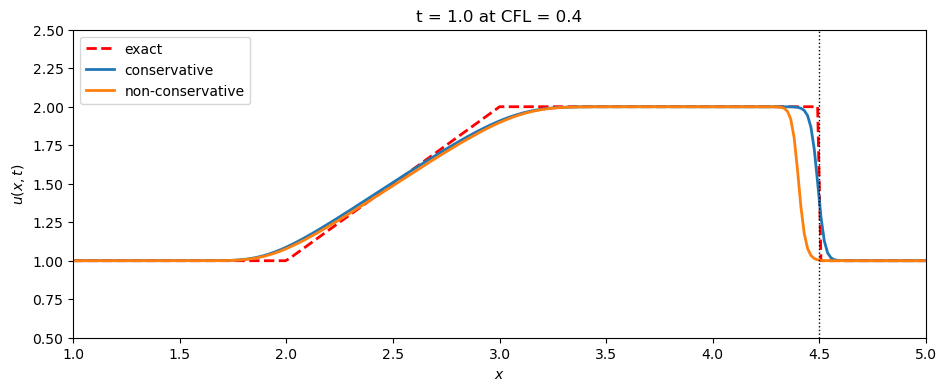

In [9]:
plt.figure(figsize=(11,4))

plt.plot(x_in, u_ex, color = "red", ls = "--", lw = 2, label = "exact")
plt.plot(x_in, u_cons[:, -1], lw = 2, label = "conservative")
plt.plot(x_in, u_prim[:, -1], lw = 2, label = "non-conservative")

plt.axvline(xb + s_exact*t_end, color = "k", lw = 1, ls = ":")

plt.xlabel(r"$x$")
plt.ylabel(r"$u(x,t)$")

plt.title(f"t = {t_end} at CFL = {cfl}")

plt.xlim(1., 5.)
plt.ylim(0.5, 2.5)

plt.legend()

plt.show()

### 6. Measuring the shock speed:

The shock position is where the falling edge crosses the mean of the two states. Dividing by the elapsed time gives the speed.

In [10]:
# Function to gather shock position

def shock_position(x_vec, u_vec):

    half = 0.5*(u_hi + u_lo)

    # the falling crossing, taken from the right
    k = np.where((u_vec[:-1] >= half) & (u_vec[1:] < half))[0][0]
    #print(k)
    
    dx_num = x_vec[1] - x_vec[0]

    sh_pos = x_vec[k] + (u_vec[k] - half)/(u_vec[k] - u_vec[k+1])*dx_num

    return sh_pos

In [11]:
for name, u_mat in [("conservative", u_cons), ("non-conservative", u_prim)]:

    # Get shock position
    pos = shock_position(x_in, u_mat[:, -1])

    # Divide by t_end to get speed
    speed = (pos - xb)/t_end

    # Error in %
    err = abs(100.*(speed - s_exact)/s_exact)

    print(f"{name:18s} pos. = {pos:.4f}  speed = {speed:.4f}  " f"error = {err:.2f} %")

conservative       pos. = 4.4930  speed = 1.4930  error = 0.46 %
non-conservative   pos. = 4.4041  speed = 1.4041  error = 6.39 %


### 7. Tests at different resolutions:

If the error were a discretisation error it would fall as the mesh is refined.

The full solution matrix is too large to keep on the finest grids, so this function carries two time levels only.

In [12]:
def final_level(ni_num, form, t_final = 1., cfl_num = 0.4):

    # x axis
    x_vec = np.linspace(x_min, x_max, ni_num)

    # delta x
    dx_num = x_vec[1] - x_vec[0]

    # get time step. dt
    dt_num = cfl_num*dx_num/u_hi

    # get N
    n_steps = int(round(t_final/dt_num))

    # numerical dt
    dt_num = t_final/n_steps

    # add IC
    u_vec = square_pulse(x_vec)

    for n in range(n_steps):
        u_old = u_vec.copy()

        if form == "conservative":
            f_old = 0.5*u_old**2
            u_vec[1:] = u_old[1:] - dt_num/dx_num*(f_old[1:] - f_old[:-1])
            u_vec[0] = u_old[0] - dt_num/dx_num*(f_old[0] - 0.5*u_old[-2]**2)
        else:
            u_vec[1:] = (u_old[1:] - u_old[1:]*dt_num/dx_num*(u_old[1:] - u_old[:-1]))
            u_vec[0] = (u_old[0] - u_old[0]*dt_num/dx_num*(u_old[0] - u_old[-2]))

        u_vec[-1] = u_vec[0]

    return x_vec, u_vec

In [13]:
ni_list = [201, 401, 801, 1601, 3201]

speeds = {}

for ni_num in ni_list:

    row = []

    for form in ("conservative", "non-conservative"):

        x_vec, u_vec = final_level(ni_num, form)
        row.append((shock_position(x_vec, u_vec) - xb)/1.)

    speeds[ni_num] = row


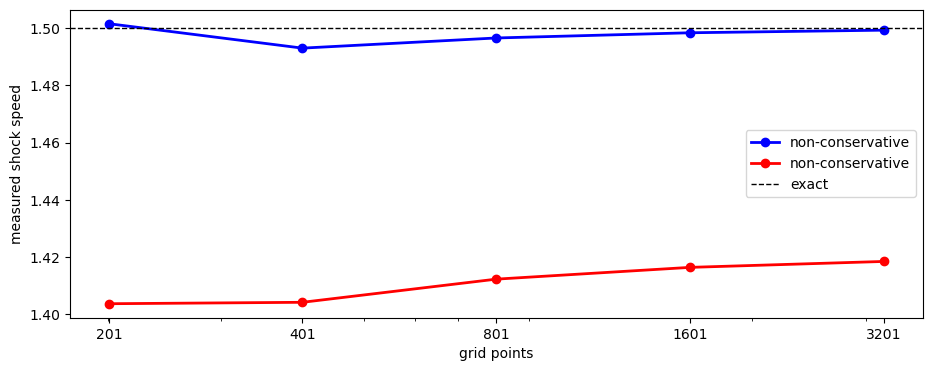

In [14]:
plt.figure(figsize=(11,4))

plt.semilogx(ni_list, [speeds[n][0] for n in ni_list], color = "blue", marker = "o", lw = 2, label = form)
plt.semilogx(ni_list, [speeds[n][1] for n in ni_list], color = "red",marker = "o", lw = 2, label = form)

plt.axhline(s_exact, color = "k", lw = 1, ls = "--", label = "exact")

plt.xticks(ni_list, [str(n) for n in ni_list])

plt.xlabel("grid points")
plt.ylabel("measured shock speed")

plt.legend()

plt.show()

# Part II. The viscous equation

The initial condition is built from a function $\phi$,

$$u = -\frac{2\mu}{\phi}\frac{\partial \phi}{\partial x} + 4, \qquad
\phi = \exp\!\left(\frac{-(x - 4t)^2}{4\mu(t+1)}\right)
+ \exp\!\left(\frac{-(x - 4t - 2\pi)^2}{4\mu(t+1)}\right),$$

which is an analytical solution of the viscous equation at every time, not only at $t = 0$.

The computed solution can be compared with it directly.

**Reference**: Barba's CFD course (https://github.com/barbagroup/CFDPython)

### 1. Domain Definition (grid creation):

In [15]:
# Number of points
ni = 101

# Resolution along x
dx = (x_max - x_min)/(ni - 1)

# Generate the x vector
x = np.linspace(x_min, x_max, ni)

### 2. The analytical solution with SymPy:

We can obtain the derivative $\partial \phi / \partial x$ with SymPy.

In [16]:
# Symbols
x_s, t_s, mu_s = sp.symbols('x t mu')

# The function phi
phi = (sp.exp(-(x_s - 4.*t_s)**2/(4.*mu_s*(t_s + 1.))) + sp.exp(-(x_s - 4.*t_s - 2.*sp.pi)**2/(4.*mu_s*(t_s + 1.))))

# Its derivative
dphi_dx = phi.diff(x_s)

# The full solution
u_sym = -2.*mu_s*(dphi_dx/phi) + 4.

#print(u_sym)
display(u_sym)

-2.0*mu*(-0.25*(-8.0*t + 2*x)*exp(-0.25*(-4.0*t + x)**2/(mu*(t + 1.0)))/(mu*(t + 1.0)) - 0.25*(-8.0*t + 2*x - 4.0*pi)*exp(-0.25*(-4.0*t + x - 2.0*pi)**2/(mu*(t + 1.0)))/(mu*(t + 1.0)))/(exp(-0.25*(-4.0*t + x - 2.0*pi)**2/(mu*(t + 1.0))) + exp(-0.25*(-4.0*t + x)**2/(mu*(t + 1.0)))) + 4.0

In [17]:
# Turn the symbolic expression into a callable function
u_exact_fn = sp.lambdify((t_s, x_s, mu_s), u_sym)

# Safe check
print(u_exact_fn(1., 4., 3.).round(3))


3.492


### 3. Set up ICs/BCs:

The initial condition is the analytical solution evaluated at $t = 0$.

The boundary condition is periodic, $u(0, t) = u(2\pi, t)$.

In [18]:
# Viscosity
mu = 0.07

# Initial condition
ics = np.array([u_exact_fn(0., x_i, mu) for x_i in x])

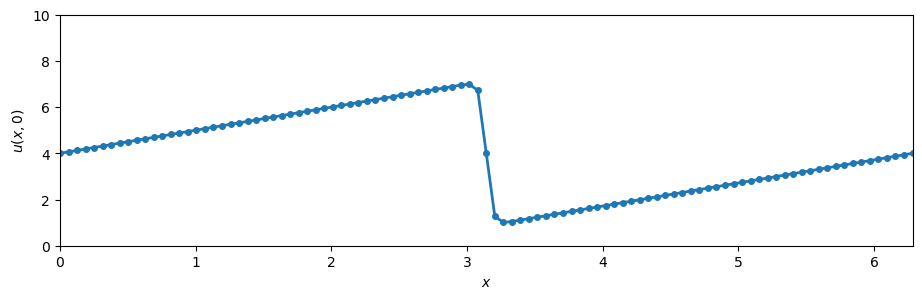

In [19]:
# Plotting
plt.figure(figsize=(11,3))

plt.plot(x, ics, marker = "o", ms = 4, lw = 2)

plt.xlabel(r"$x$")
plt.ylabel(r"$u(x,0)$")

plt.xlim(x_min, x_max)
plt.ylim(0, 10)

plt.show()

### 4. Time discretisation:

We can take $\Delta t = \mu\,\Delta x$, which keeps both the convective and the diffusive restrictions satisfied on this grid.

In [20]:
# Time step
dt = mu*dx

# Number of time levels
nt = 101

# Time axis
t = np.arange(0., nt*dt, dt)

### 5. Numerical integration, in both forms:

Forward in time and centred for the viscous term.

The convective term is written in two ways, as on the slides:

$$
\begin{aligned}
\text{conservative:} \quad & u_i^{\,n+1} = u_i^{\,n}
 - \frac{\Delta t}{\Delta x}\left( F_i^{\,n} - F_{i-1}^{\,n} \right)
 + \mu\frac{\Delta t}{\Delta x^2}
 \left( u_{i+1}^{\,n} - 2u_i^{\,n} + u_{i-1}^{\,n} \right) \\[4pt]
\text{non-conservative:} \quad & u_i^{\,n+1} = u_i^{\,n}
 - u_i^{\,n}\frac{\Delta t}{\Delta x}
 \left( u_i^{\,n} - u_{i-1}^{\,n} \right)
 + \mu\frac{\Delta t}{\Delta x^2}
 \left( u_{i+1}^{\,n} - 2u_i^{\,n} + u_{i-1}^{\,n} \right)
\end{aligned}
$$

In [21]:
def march_viscous(ics_vec, form, mu_num, dt_num, dx_num, n_levels):

    # Sln array
    u_mat = np.zeros((len(ics_vec), n_levels))

    # ICs
    u_mat[:, 0] = ics_vec

    # time loop (index n)
    for n in range(1, n_levels):

        u_old = u_mat[:, n-1]

        # the viscous term is the same in both forms
        visc = np.zeros_like(u_old)
        visc[1:-1] = u_old[2:] - 2.*u_old[1:-1] + u_old[:-2]
        visc[0] = u_old[1] - 2.*u_old[0] + u_old[-2]

        if form == "conservative":
            f_old = 0.5*u_old**2

            conv = np.zeros_like(u_old)
            conv[1:-1] = f_old[1:-1] - f_old[:-2]
            conv[0] = f_old[0] - 0.5*u_old[-2]**2

        else:
            conv = np.zeros_like(u_old)
            conv[1:-1] = u_old[1:-1]*(u_old[1:-1] - u_old[:-2])
            conv[0] = u_old[0]*(u_old[0] - u_old[-2])

        u_mat[:-1, n] = (u_old[:-1] - dt_num/dx_num*conv[:-1] + mu_num*dt_num/dx_num**2*visc[:-1])

        u_mat[-1, n] = u_mat[0, n]

    return u_mat

In [22]:
u_cons_v = march_viscous(ics, "conservative", mu, dt, dx, nt)
u_prim_v = march_viscous(ics, "non-conservative", mu, dt, dx, nt)

#print(u_cons_v.shape, u_prim_v.shape)

### 6. Comparison with the analytical solution:

In [23]:
# The analytical solution at the final time
u_ref = np.array([u_exact_fn(t[-1], x_i, mu) for x_i in x])

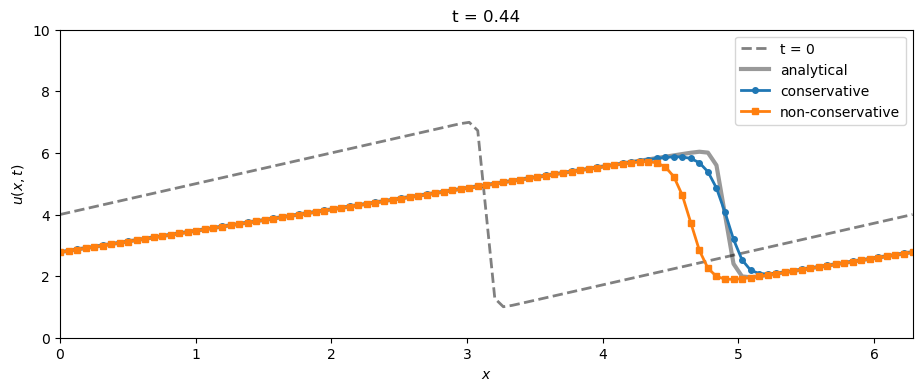

In [24]:
# Plotting
plt.figure(figsize=(11,4))

plt.plot(x, ics, color = "0.5", ls = "--", lw = 2, label = "t = 0")
plt.plot(x, u_ref, color = "k", lw = 3, alpha = 0.4, label = "analytical")
plt.plot(x, u_cons_v[:, -1], marker = "o", ms = 4, lw = 2, label = "conservative")
plt.plot(x, u_prim_v[:, -1], marker = "s", ms = 4, lw = 2, label = "non-conservative")

plt.xlabel(r"$x$")
plt.ylabel(r"$u(x,t)$")

plt.title(f"t = {t[-1]:.2f}")

plt.xlim(x_min, x_max)
plt.ylim(0, 10)

plt.legend()

plt.show()

### Observations:

#### Part I: 

- the conservative form puts the shock at $x = 4.5$ at $t = 1$, which is the Rankine-Hugoniot speed $s = (u_1 + u_2)/2 = 1.5$.

- The non-conservative form puts it at $x = 4.404$ on the same mesh, a speed of 1.404.

- Refining the mesh does not remove that error. The conservative values approach 1.5 and the non-conservative ones approach a different number, so the non-conservative scheme is converging to a solution of a different problem.

- The reason is the **telescoping sum**. A scheme written as a difference of fluxes conserves $\sum u$ exactly at any mesh size. 

- The non-conservative form has no flux difference, so nothing cancels, and the discrete
  conservation statement that the shock speed follows from is not enforced.

#### Part II:

- With $\mu = 0.07$ the front of the saw-tooth is only two or three cells wide, so the same thing happens on a profile that is not even discontinuous.

- The conservative form lands on the analytical curve; the non-conservative form leaves the front behind by about 0.27 in $x$, and the largest error grows from 0.79 to 3.75.
